PRCP-1002: Handwritten Digits Recognition

1. Project Introduction

1.1 Objective

The objective of this project is to develop a machine learning model that can recognise handwritten digits from images.

The model will classify handwritten digit images into ten different categories, from 0 to 9.

1.2 Problem Statement

Handwritten digits can look different depending on the person writing them. This makes automatic recognition a challenging task.

In this project, we will use the MNIST dataset to train and evaluate different machine learning models and identify the best-performing classifier.

1.3 Project Goals

Understand and analyse the MNIST dataset.

Explore and visualise handwritten digit images.

Prepare the data for machine learning.

Train multiple classification models.

Compare model performance.

Select the most suitable model.

Document challenges, solutions and recommendations.

## 2. Dataset Understanding

### 2.1 About the MNIST Dataset

MNIST is a widely used dataset for handwritten digit recognition.

It contains 70,000 grayscale images of handwritten digits ranging from 0 to 9.

### 2.2 Dataset Characteristics

- Total images: 70,000
- Training images: 60,000
- Testing images: 10,000
- Image dimensions: 28 × 28 pixels
- Number of classes: 10
- Pixel intensity range: 0 to 255

### 2.3 Training and Testing Data

The training dataset contains 60,000 images used to teach the machine learning models to recognise handwritten digits.

The testing dataset contains 10,000 separate images used to evaluate how well the trained models recognise previously unseen digits.

### 2.4 Pixel Information

Each image contains 28 rows and 28 columns, giving a total of 784 pixels.

Each pixel represents a grayscale intensity value between 0 and 255.

These pixel values are used as input features by machine learning models.

In [12]:
from tensorflow.keras.datasets import mnist

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


In [14]:
print("First five training labels:")
print(y_train[:5])

First five training labels:
[5 0 4 1 9]


In [15]:
import matplotlib.pyplot as plt

print("Matplotlib is working!")

Matplotlib is working!


In [16]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [17]:
import matplotlib.pyplot as plt

print("Matplotlib is working!")

Matplotlib is working!


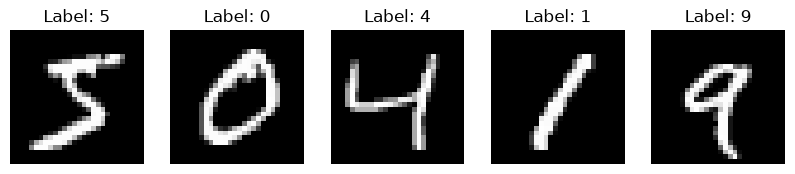

In [18]:
# Display the first five training images
plt.figure(figsize=(10, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

In [19]:
print("Image shape:", x_train[0].shape)

print("Minimum pixel value:", x_train[0].min())

print("Maximum pixel value:", x_train[0].max())

print("Pixel values of the first 5 rows:")
print(x_train[0][:5])

Image shape: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255
Pixel values of the first 5 rows:
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]


In [20]:
import numpy as np

# Count the number of images for each digit
unique_digits, digit_counts = np.unique(y_train, return_counts=True)

print("Digit distribution in training data:")

for digit, count in zip(unique_digits, digit_counts):
    print(f"Digit {digit}: {count} images")

Digit distribution in training data:
Digit 0: 5923 images
Digit 1: 6742 images
Digit 2: 5958 images
Digit 3: 6131 images
Digit 4: 5842 images
Digit 5: 5421 images
Digit 6: 5918 images
Digit 7: 6265 images
Digit 8: 5851 images
Digit 9: 5949 images


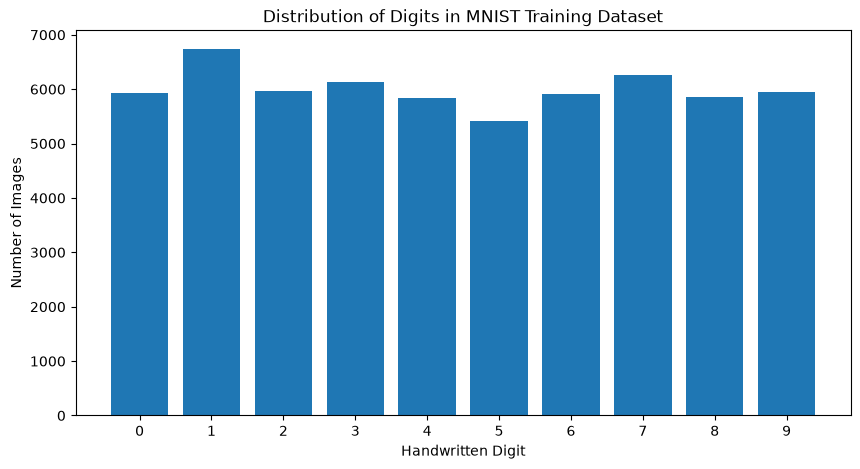

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(unique_digits, digit_counts)

plt.xlabel("Handwritten Digit")
plt.ylabel("Number of Images")
plt.title("Distribution of Digits in MNIST Training Dataset")

plt.xticks(unique_digits)
plt.show()

Exploratory Data Analysis (EDA)

1. Visual Inspection of Images

The first five images from the MNIST training dataset were displayed to understand the handwritten digits.

Each image has dimensions of 28 × 28 pixels and represents one handwritten digit from 0 to 9.

2. Pixel Value Analysis

The pixel values range from 0 to 255.

0 represents black.

255 represents white.

Values between 0 and 255 represent different shades of grey.

Each image contains 784 pixels.

3. Distribution of Digit Classes

The training dataset contains 60,000 images across 10 digit classes.

The class distribution shows:

Digit 1 has the highest number of images (6,742).

Digit 5 has the lowest number of images (5,421).

All 10 digit classes are represented.

The dataset is reasonably balanced, although the number of images varies slightly between classes.

4. EDA Conclusion

The initial analysis confirms that the MNIST dataset contains labelled grayscale images suitable for handwritten digit classification.

The image dimensions, pixel values and class distribution have been examined. This provides a foundation for the next stage of data preprocessing and model development.

In [22]:
# Check the original pixel value range

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Data type:", x_train.dtype)

Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8


In [23]:
# Normalize pixel values to the range 0 to 1

x_train_normalized = x_train / 255.0
x_test_normalized = x_test / 255.0

print("Normalization completed!")

Normalization completed!


In [24]:
print("Training data:")
print("Minimum pixel value:", x_train_normalized.min())
print("Maximum pixel value:", x_train_normalized.max())
print("Data type:", x_train_normalized.dtype)

print("\nTesting data:")
print("Minimum pixel value:", x_test_normalized.min())
print("Maximum pixel value:", x_test_normalized.max())
print("Data type:", x_test_normalized.dtype)

Training data:
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float64

Testing data:
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float64


In [25]:
# Flatten the 28x28 images into 784 pixel values

x_train_flattened = x_train_normalized.reshape(60000, 784)
x_test_flattened = x_test_normalized.reshape(10000, 784)

print("Training data shape:", x_train_flattened.shape)
print("Testing data shape:", x_test_flattened.shape)

Training data shape: (60000, 784)
Testing data shape: (10000, 784)


In [26]:
print("Original image shape:", x_train_normalized[0].shape)
print("Flattened image shape:", x_train_flattened[0].shape)

print("First 10 pixel values:")
print(x_train_flattened[0][:10])

Original image shape: (28, 28)
Flattened image shape: (784,)
First 10 pixel values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


Data Preprocessing

Data preprocessing was performed to prepare the MNIST dataset for machine learning models.

1. Normalization

The original pixel values ranged from 0 to 255. Both training and testing images were normalized by dividing each pixel value by 255.0.

After normalization, pixel values ranged from 0.0 to 1.0.

2. Flattening

Each MNIST image originally had a shape of 28 × 28 pixels, containing 784 pixel values.

The images were flattened into one-dimensional arrays containing 784 values each.

Training data shape: (60000, 784)

Testing data shape: (10000, 784)

3. Preserving Original Image Structure

The normalized 28 × 28 images were retained separately. The flattened images will be used for traditional machine learning algorithms such as KNN, SVM and Logistic Regression.

The original image structure can also be used if a Convolutional Neural Network (CNN) is implemented.

Conclusion

Normalization and flattening were completed successfully. The dataset is now prepared for the next stage of machine learning model development.

In [27]:
# Verify the preprocessed dataset

print("Training images:", x_train_flattened.shape)
print("Testing images:", x_test_flattened.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 784)
Testing images: (10000, 784)
Training labels: (60000,)
Testing labels: (10000,)


In [28]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [29]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [30]:
print("Training images:", x_train_flattened.shape)
print("Testing images:", x_test_flattened.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 784)
Testing images: (10000, 784)
Training labels: (60000,)
Testing labels: (10000,)


In [31]:
# Import the KNN classifier

from sklearn.neighbors import KNeighborsClassifier

print("KNN classifier imported successfully!")

KNN classifier imported successfully!


In [32]:
# Create the KNN model

knn_model = KNeighborsClassifier(n_neighbors=5)

print("KNN model created successfully!")

KNN model created successfully!


In [33]:
from sklearn.neighbors import KNeighborsClassifier

print("KNN classifier imported successfully!")

KNN classifier imported successfully!


In [34]:
# Create the KNN model

knn_model = KNeighborsClassifier(n_neighbors=5)

print("KNN model created successfully!")

KNN model created successfully!


In [35]:
# Select 10,000 training images
x_train_sample, _, y_train_sample, _ = train_test_split(
    x_train_flattened,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42
)

# Select 2,000 testing images
x_test_sample, _, y_test_sample, _ = train_test_split(
    x_test_flattened,
    y_test,
    train_size=2000,
    stratify=y_test,
    random_state=42
)

print("Training sample shape:", x_train_sample.shape)
print("Testing sample shape:", x_test_sample.shape)

Training sample shape: (10000, 784)
Testing sample shape: (2000, 784)


In [36]:
from sklearn.model_selection import train_test_split

print("train_test_split imported successfully!")

train_test_split imported successfully!


In [37]:
print(x_train_sample.shape)

(10000, 784)


In [38]:
# Select 10,000 training images
x_train_sample, _, y_train_sample, _ = train_test_split(
    x_train_flattened,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42
)

# Select 2,000 testing images
x_test_sample, _, y_test_sample, _ = train_test_split(
    x_test_flattened,
    y_test,
    train_size=2000,
    stratify=y_test,
    random_state=42
)

print("Training sample shape:", x_train_sample.shape)
print("Testing sample shape:", x_test_sample.shape)

Training sample shape: (10000, 784)
Testing sample shape: (2000, 784)


In [39]:
# Train the KNN model

import time

start_time = time.time()

knn_model.fit(x_train_sample, y_train_sample)

end_time = time.time()

knn_training_time = end_time - start_time

print("KNN model training completed!")
print("Training time:", round(knn_training_time, 2), "seconds")

KNN model training completed!
Training time: 0.04 seconds


In [40]:
# Make predictions using the KNN model

start_time = time.time()

y_pred_knn = knn_model.predict(x_test_sample)

end_time = time.time()

knn_prediction_time = end_time - start_time

print("KNN predictions completed!")
print("Prediction time:", round(knn_prediction_time, 2), "seconds")

KNN predictions completed!
Prediction time: 0.55 seconds


In [41]:
# Evaluate KNN model accuracy

from sklearn.metrics import accuracy_score

knn_accuracy = accuracy_score(y_test_sample, y_pred_knn)

print("KNN Model Accuracy:", round(knn_accuracy * 100, 2), "%")

KNN Model Accuracy: 94.55 %


In [42]:
# Generate KNN classification report

from sklearn.metrics import classification_report

print(classification_report(y_test_sample, y_pred_knn))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       196
           1       0.91      0.99      0.95       227
           2       0.98      0.91      0.94       206
           3       0.93      0.94      0.94       202
           4       0.96      0.93      0.95       196
           5       0.95      0.92      0.93       178
           6       0.97      0.98      0.97       192
           7       0.92      0.94      0.93       206
           8       0.99      0.90      0.94       195
           9       0.89      0.94      0.92       202

    accuracy                           0.95      2000
   macro avg       0.95      0.94      0.95      2000
weighted avg       0.95      0.95      0.95      2000



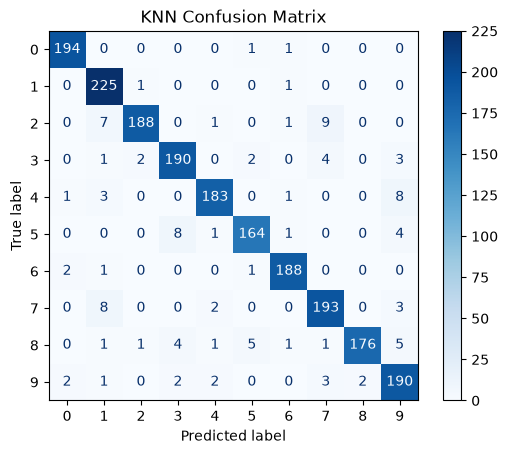

In [43]:
# Create the KNN confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_sample, y_pred_knn)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()

The K-Nearest Neighbors (KNN) model was trained using
10,000 training images and evaluated using 2,000 test images.

- Number of neighbours (K): 5
- Training time: 0.04 seconds
- Prediction time: 0.55 seconds
- Accuracy: 94.55%

The classification report showed an overall weighted
F1-score of approximately 0.95.

The confusion matrix showed that the model performed
well on most digits. Some confusion was observed between
digits 2 and 7, 4 and 9, and 5 and 3.

The model correctly classified 1,891 out of 2,000
test images and incorrectly classified 109 images.

These results represent the selected test sample and
not the complete MNIST test dataset.

In [44]:
error_matrix = cm.copy()

# Remove correct predictions (diagonal)
np.fill_diagonal(error_matrix, 0)

# Find the five largest errors
error_indices = np.dstack(
    np.unravel_index(
        np.argsort(error_matrix.ravel())[-5:][::-1],
        error_matrix.shape
    )
)[0]

print("Five most common classification errors:\n")

for actual, predicted in error_indices:
    print(
        f"Actual digit: {actual}, "
        f"Predicted digit: {predicted}, "
        f"Errors: {error_matrix[actual, predicted]}"
    )

Five most common classification errors:

Actual digit: 2, Predicted digit: 7, Errors: 9
Actual digit: 7, Predicted digit: 1, Errors: 8
Actual digit: 4, Predicted digit: 9, Errors: 8
Actual digit: 5, Predicted digit: 3, Errors: 8
Actual digit: 2, Predicted digit: 1, Errors: 7


In [45]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [46]:
# Create the Logistic Regression model

lr_model = LogisticRegression(max_iter=1000)

print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


In [48]:
# Train the Logistic Regression model

start_time = time.time()

lr_model.fit(x_train_sample, y_train_sample)

end_time = time.time()

lr_training_time = end_time - start_time

print("Logistic Regression training completed!")
print("Training time:", round(lr_training_time, 2), "seconds")

Logistic Regression training completed!
Training time: 63.43 seconds


In [49]:
# Make predictions using Logistic Regression

start_time = time.time()

y_pred_lr = lr_model.predict(x_test_sample)

end_time = time.time()

lr_prediction_time = end_time - start_time

print("Logistic Regression predictions completed!")
print("Prediction time:", round(lr_prediction_time, 2), "seconds")

Logistic Regression predictions completed!
Prediction time: 0.02 seconds


In [50]:
# Evaluate Logistic Regression accuracy

lr_accuracy = accuracy_score(y_test_sample, y_pred_lr)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 91.05 %


In [51]:
# Generate Logistic Regression classification report

print(classification_report(y_test_sample, y_pred_lr))

              precision    recall  f1-score   support

           0       0.91      0.98      0.94       196
           1       0.93      0.97      0.95       227
           2       0.92      0.86      0.89       206
           3       0.90      0.90      0.90       202
           4       0.94      0.91      0.93       196
           5       0.87      0.86      0.86       178
           6       0.94      0.91      0.93       192
           7       0.92      0.93      0.92       206
           8       0.87      0.86      0.86       195
           9       0.90      0.91      0.90       202

    accuracy                           0.91      2000
   macro avg       0.91      0.91      0.91      2000
weighted avg       0.91      0.91      0.91      2000



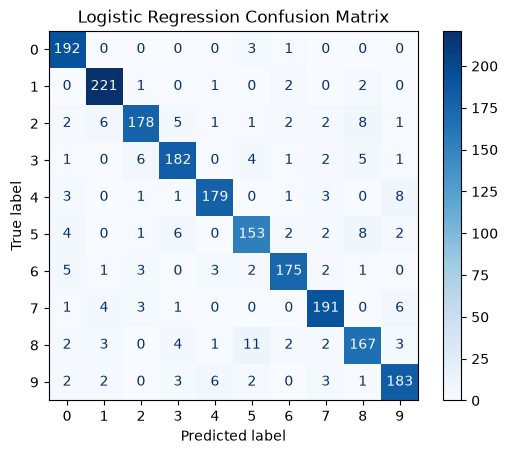

In [52]:
# Create Logistic Regression confusion matrix

cm_lr = confusion_matrix(y_test_sample, y_pred_lr)

display_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=range(10)
)

display_lr.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [53]:
# Find the five most common Logistic Regression errors

error_matrix_lr = cm_lr.copy()

# Remove correct predictions
np.fill_diagonal(error_matrix_lr, 0)

# Find the five largest errors
error_indices_lr = np.dstack(
    np.unravel_index(
        np.argsort(error_matrix_lr.ravel())[-5:][::-1],
        error_matrix_lr.shape
    )
)[0]

print("Five most common Logistic Regression errors:\n")

for actual, predicted in error_indices_lr:
    print(
        f"Actual digit: {actual}, "
        f"Predicted digit: {predicted}, "
        f"Errors: {error_matrix_lr[actual, predicted]}"
    )

Five most common Logistic Regression errors:

Actual digit: 8, Predicted digit: 5, Errors: 11
Actual digit: 2, Predicted digit: 8, Errors: 8
Actual digit: 4, Predicted digit: 9, Errors: 8
Actual digit: 5, Predicted digit: 8, Errors: 8
Actual digit: 5, Predicted digit: 3, Errors: 6


Logistic Regression Model Evaluation

The Logistic Regression model was trained using 10,000 training images and evaluated using 2,000 test images.

Model configuration:

Maximum iterations: 1,000

Performance results:

Training time: 63.43 seconds

Prediction time: 0.02 seconds

Accuracy: 91.05%

Correct predictions: 1,821

Incorrect predictions: 179

Classification report observations:

Digit 1 achieved the highest F1-score of 0.95.

Digit 0 achieved a recall of 0.98.

Digits 5 and 8 had the lowest F1-scores of 0.86.

Five most common classification errors:

Actual digit  Predicted digit  Errors

8                  5              11         

2                  8               8

4                  9               8

5                  8               8

5                  3               6

Conclusion:

Logistic Regression achieved 91.05% accuracy on the selected test sample. It had a longer training time than KNN but a much shorter prediction time.

KNN achieved higher accuracy in this experiment (94.55%). Further model comparisons are required before selecting the final classifier.

These results are based on the selected 2,000 test images and not the complete MNIST test dataset.